In [6]:
"""
Equation:(time in units of tau_w / (q_S - q_D)):

    dw(a)/dt = sum over b of K(a - b) * w(b)

where w(a) = w_R(a) - w_L(a) is the eye preference at site a.
"""

import numpy as np
import matplotlib.pyplot as plt


N = 200                    # number of sites on the ring
sigma_e = 1.0              # width of the excitation (narrow bump)
sigma_i_list = [2.0, 3.0]  # widths of the inhibition (wide bump) 
dt = 0.02                  # Euler time step
t_end = 40.0               # final time
n_steps = int(t_end / dt)  # 40 / 0.02 = 2000 steps
n_runs = 20                # number of random initial conditions per sigma_i

rng = np.random.default_rng(4370)   # fixed seed so results repeat


#  The Mexican hat kernel K(x)

def K(x, sigma_i):
    excitation = np.exp(-x**2 / (2 * sigma_e**2))
    inhibition = (sigma_e / sigma_i) * np.exp(-x**2 / (2 * sigma_i**2))
    return excitation - inhibition


def ring_distance(a, b):
    """Shortest distance between sites a and b going around the ring."""
    d = abs(a - b)
    return min(d, N - d)


def build_K_matrix(sigma_i):
    """Kmat[a, b] = K(distance from a to b). Row a holds the weights site a gives every site b."""
    Kmat = np.zeros((N, N))
    for a in range(N):
        for b in range(N):
            Kmat[a, b] = K(ring_distance(a, b), sigma_i)
    return Kmat


#  simulation with forward Euler

def simulate(Kmat):
    w = 0.01 * rng.standard_normal(N)      # w(a) at t = 0: tiny random noise, std 0.01

    for step in range(n_steps):
        dwdt = Kmat @ w                    # dw(a)/dt = sum_b K(a-b) w(b), for every a at once
        w = w + dt * dwdt                  # Euler: w(t + dt) = w(t) + dt * dw/dt
        w = np.clip(w, -1.0, 1.0)          # keep every w(a) inside [-1, 1]

    return w


# Measuring the stripes

def count_stripe_pairs(w):
    """Count sign changes around the ring. Each right+left pair has 2 edges."""
    changes = 0
    for a in range(N):
        if np.sign(w[a]) != np.sign(w[a - 1]):   # w[-1] is the last site, so the ring wraps
            changes += 1
    return changes / 2



def K_tilde(k, sigma_i):
    """Fourier transform of K: growth rate of the wave e^{ika} (continuous cortex)."""
    return sigma_e * np.sqrt(2 * np.pi) * (np.exp(-sigma_e**2 * k**2 / 2) - np.exp(-sigma_i**2 * k**2 / 2))


def k_star(sigma_i):
    """Fastest-growing wavenumber: k*^2 = 4 ln(sigma_i/sigma_e) / (sigma_i^2 - sigma_e^2)."""
    return np.sqrt(4 * np.log(sigma_i / sigma_e) / (sigma_i**2 - sigma_e**2))


def ring_growth_rate(m, sigma_i):
    """Growth rate of a wave with exactly m wavelengths around the ring: sum_d K(d) cos(2 pi m d / N)."""
    rate = 0.0
    for d in range(N):
        rate += K(ring_distance(d, 0), sigma_i) * np.cos(2 * np.pi * m * d / N)
    return rate



m_values = np.arange(1, N // 2 + 1)    # whole numbers of waves that fit: 1, 2, ..., 100
final_patterns = {}                    # one example pattern per sigma_i, for plotting
ring_rates = {}                        # growth rate of every ring mode, for plotting

for sigma_i in sigma_i_list:
    # theory: continuous cortex
    ks = k_star(sigma_i)
    period_continuum = 2 * np.pi / ks

    # theory: the best whole number of waves on the ring
    rates = np.array([ring_growth_rate(m, sigma_i) for m in m_values])
    m_best = m_values[np.argmax(rates)]
    period_ring = N / m_best

    # simulation: 20 random starts
    Kmat = build_K_matrix(sigma_i)
    pairs_list = []
    periods = []
    for run in range(n_runs):
        w = simulate(Kmat)
        pairs = count_stripe_pairs(w)
        pairs_list.append(int(pairs))
        periods.append(N / pairs)
        if run == 0:
            final_patterns[sigma_i] = w
    periods = np.array(periods)
    ring_rates[sigma_i] = rates

    print(f"sigma_i = {sigma_i}")
    print(f"  k* = {ks:.4f}, continuum period 2*pi/k* = {period_continuum:.4f}")
    print(f"  best ring mode m = {m_best}, ring period N/m = {period_ring:.4f}")
    print(f"  stripe pairs in each run: {pairs_list}")
    print(f"  measured period: mean = {periods.mean():.4f}, std = {periods.std(ddof=1):.4f}")


sigma_i = 2.0
  k* = 0.9614, continuum period 2*pi/k* = 6.5358
  best ring mode m = 31, ring period N/m = 6.4516
  stripe pairs in each run: [30, 31, 31, 31, 30, 34, 32, 32, 31, 32, 32, 31, 30, 30, 29, 32, 32, 30, 29, 31]
  measured period: mean = 6.4609, std = 0.2506
sigma_i = 3.0
  k* = 0.7412, continuum period 2*pi/k* = 8.4776
  best ring mode m = 24, ring period N/m = 8.3333
  stripe pairs in each run: [26, 23, 25, 25, 24, 22, 25, 25, 24, 23, 24, 27, 25, 26, 23, 23, 26, 27, 24, 25]
  measured period: mean = 8.1549, std = 0.4632


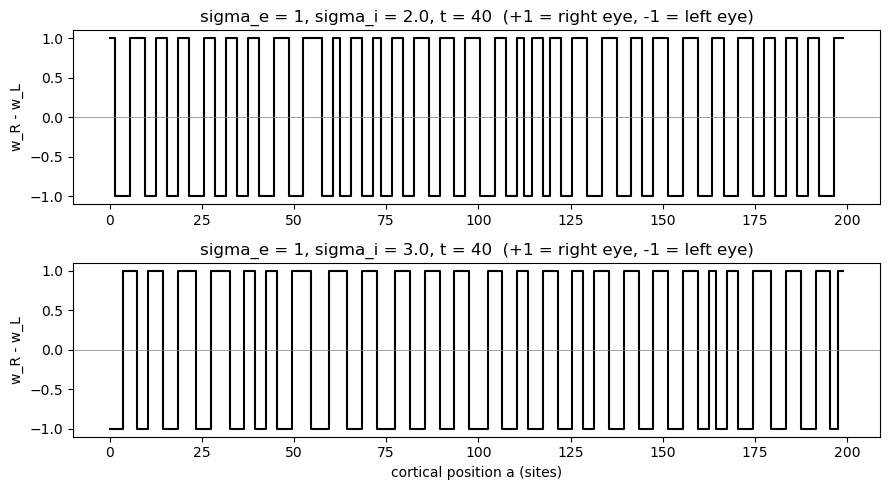

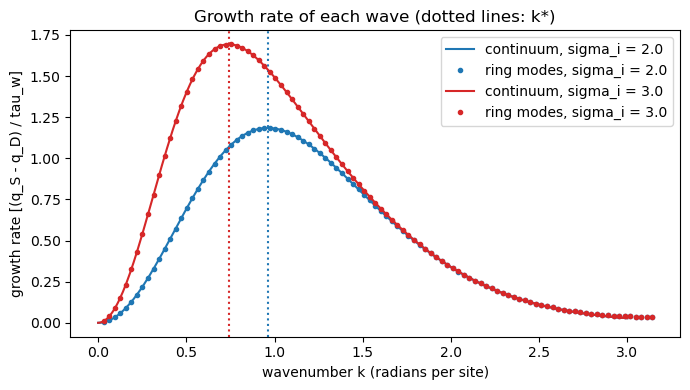

In [7]:

# Figure 1: one final pattern for each sigma_i

sites = np.arange(N)
plt.figure(figsize=(9, 5))
for i, sigma_i in enumerate(sigma_i_list):
    plt.subplot(2, 1, i + 1)                                   # 2 rows, 1 column, panel i+1
    plt.step(sites, final_patterns[sigma_i], where="mid", color="black")
    plt.axhline(0, color="gray", linewidth=0.5)
    plt.ylabel("w_R - w_L")
    plt.title(f"sigma_e = 1, sigma_i = {sigma_i}, t = 40  (+1 = right eye, -1 = left eye)")
plt.xlabel("cortical position a (sites)")
plt.tight_layout()


# 8. Figure 2: growth rate vs wavenumber
k = np.linspace(0, 3, 300)
k_ring = 2 * np.pi * m_values / N       # wavenumber of each ring mode
colors = {2.0: "tab:blue", 3.0: "tab:red"}

plt.figure(figsize=(7, 4))
for sigma_i in sigma_i_list:
    c = colors[sigma_i]
    plt.plot(k, K_tilde(k, sigma_i), color=c, label=f"continuum, sigma_i = {sigma_i}")
    plt.plot(k_ring, ring_rates[sigma_i], ".", color=c, label=f"ring modes, sigma_i = {sigma_i}")
    plt.axvline(k_star(sigma_i), color=c, linestyle=":")
plt.xlabel("wavenumber k (radians per site)")
plt.ylabel("growth rate [(q_S - q_D) / tau_w]")
plt.title("Growth rate of each wave (dotted lines: k*)")
plt.legend()
plt.tight_layout()

plt.show()